# Transformation optics and the cylindrical cloak

Can the recipe "medium = pulled-back vacuum" be turned into a computable object, and how fragile is the resulting cylindrical cloak? We implement the recipe with automatic differentiation, write down the exact cloaked field, build a partial-wave solver for radially varying anisotropic cylinders, and then perturb the cloak (truncated lining, reduced parameters, loss, layering, dispersion).

## What this notebook shows

- The medium of any coordinate map follows from one Jacobian (`jax.jacfwd`); the cylindrical and spherical cloak parameters of the book, and the folded-space reading of $\varepsilon=\mu=-1$, drop out of it.
- The exact field of the ideal cylindrical cloak is the virtual-space field pulled back by the map; it satisfies the anisotropic wave equation to rounding error.
- A radial ODE for $(E_z, F)$ gives all partial-wave coefficients of a radially varying cloak; it is validated against closed forms and against `bayes_scatter.mie`.
- A cloak truncated at $r=a+\delta$ scatters like a bare wire in virtual space. With a PEC or dielectric lining the $m=0$ term decays only logarithmically as $\delta\to0$; with a PMC lining it decays like $\delta^4$.
- The reduced (microwave) parameters keep the ray paths but not the scattering; loss, layering and dispersion each have their own signature in $\sigma$.

## Conventions

Time dependence $e^{-i\omega t}$: outgoing waves are Hankel functions $H_m\equiv H_m^{(1)}$, loss is a positive imaginary part of $\varepsilon$ or $\mu$. Lengths are in free-space wavelengths at the design frequency, so $\lambda_0=1$ and $k_0=2\pi$. The polarization with $E$ along $z$ is called TM ($E_z$) here, as in the project's `DESIGN.md`; the book calls it TE. The cloak has inner radius $a=1$ and outer radius $b=2$. The Helmholtz equation has the physical sign, $\nabla^2E+k^2n^2E=0$ (the book's (27.6) and (27.8) differ: misprint E5.1 in the reading notes). Section numbers refer to Leonhardt and Philbin, *Geometry and Light*.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

# Figure style shared by every notebook in notebooks/cloaking (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib
_src = pathlib.Path.cwd().resolve().parents[1] / "src"   # use the bayes_scatter that ships with this checkout
if (_src / "bayes_scatter").is_dir() and str(_src) not in sys.path:
    sys.path.insert(0, str(_src))

from scipy.integrate import solve_ivp
from scipy.special import jv, yv, jvp, yvp, hankel1, h1vp
from scipy.optimize import brentq
from bayes_scatter.mie import mie_coefficients

a, b, K0 = 1.0, 2.0, 2 * np.pi            # inner radius, outer radius, free-space wave number (design frequency)
BARE, PEC_C, PMC_C, DIEL_C, REDUCED_C = CAT[1], CAT[0], CAT[2], CAT[3], CAT[6]   # colors fixed for the whole notebook
SCA_C, ABS_C = CAT[4], CAT[7]                                                       # sigma_sca and sigma_abs: never a lining color

## 1. The recipe, with automatic differentiation

Let $x=f(x')$ map virtual space (vacuum, Cartesian coordinates $x'$) into physical space, with Jacobian $\Lambda=\partial x/\partial x'$. A medium with

$$\varepsilon=\mu=\frac{\Lambda\Lambda^{T}}{\det\Lambda}\qquad\text{(Cartesian components)}$$

carries, for every solution of Maxwell's equations in vacuum, a solution of Maxwell's equations in the medium, obtained by pulling the fields back along the inverse map $f^{-1}$, from physical to virtual space (book (32.5) for flat virtual space; the general statements are (26.7) and (28.3)). The $\pm$ of (26.7) is the handedness of the map, which is why $\det\Lambda$ rather than $|\det\Lambda|$ appears. We implement it as `medium_from_map` and test three cases.

- **Cylindrical cloak**, $r=a+r'(b-a)/b$ with angle and $z$ unchanged: $\varepsilon_r=(r-a)/r$, $\varepsilon_\theta=r/(r-a)$, $\varepsilon_z=\big(\tfrac{b}{b-a}\big)^2(r-a)/r$ (book (32.16), (32.19) for a general radial map), with the principal axes radial, azimuthal and $z$.
- **Spherical cloak**, the same radial map in 3-D: $\varepsilon_r=\tfrac{b}{b-a}(r-a)^2/r^2$, $\varepsilon_\theta=\varepsilon_\phi=\tfrac{b}{b-a}$ (book (33.4); (33.3) is the contravariant form and (33.5) the product rule).
- **Reflection** $x'\to-x'$: $\Lambda=\mathrm{diag}(-1,1,1)$, $\det\Lambda=-1$, hence $\varepsilon=\mu=-1$. This is the folded-space reading of the negative-index slab (section 34, (34.1)-(34.2)). The identity is local; CLAIMS.md H5 records that for a source inside the imaging range the pulled-back field has three singular preimages, i.e. it solves a three-source problem, so the fold alone does not give a one-source perfect lens.

In [3]:
def medium_from_map(f, xp):
    """eps = mu = Lam Lam^T / det Lam at the virtual point xp, with Lam = dx/dx' from forward-mode autodiff."""
    Lam = jax.jacfwd(f)(xp)
    return Lam @ Lam.T / jnp.linalg.det(Lam)


def radial_map(dim):
    """r = a + (b - a) r'/b on the first `dim` coordinates (dim = 2: cylinder, 3: sphere); angles and z unchanged."""
    def f(xp):
        rp = jnp.sqrt(jnp.sum(xp[:dim] ** 2))
        return xp.at[:dim].multiply((a + (b - a) * rp / b) / rp)
    return f


cyl_map, sph_map = radial_map(2), radial_map(3)
rng = np.random.default_rng(1)


def principal_values_error(f, dim, expected, n=100):
    """Max relative error of the eigenvalues and of the radial eigenvector residual over n random virtual points."""
    e_val = e_vec = 0.0
    for _ in range(n):
        u = rng.normal(size=3)
        if dim == 2:
            u[2] = 0.0
        u /= np.linalg.norm(u)
        rp = rng.uniform(0.1, b)
        xp = rp * u + (np.array([0.0, 0.0, rng.uniform(-1, 1)]) if dim == 2 else 0.0)
        r = a + (b - a) * rp / b
        eps = np.array(medium_from_map(f, jnp.array(xp)))
        want = np.array(expected(r))
        e_val = max(e_val, np.max(np.abs(np.linalg.eigvalsh(eps) - np.sort(want)) / np.sort(want)))
        e_vec = max(e_vec, np.linalg.norm(eps @ u - want[0] * u) / want[0])   # want[0] is the radial value
    return e_val, e_vec


cyl_expected = lambda r: ((r - a) / r, r / (r - a), (b / (b - a)) ** 2 * (r - a) / r)
sph_expected = lambda r: (b / (b - a) * (r - a) ** 2 / r**2, b / (b - a), b / (b - a))
for name, f, dim, exp_ in (("cylindrical cloak", cyl_map, 2, cyl_expected), ("spherical cloak", sph_map, 3, sph_expected)):
    e_val, e_vec = principal_values_error(f, dim, exp_)
    # tolerance 1e-12: float64 rounding of a Jacobian product, amplified by at most the condition number (~1e2) of the entries
    check(f"{name}: principal values, max rel. error", e_val, 1e-12)
    check(f"{name}: radial eigenvector residual", e_vec, 1e-12)

fold = lambda xp: jnp.array([-xp[0], xp[1], xp[2]])
eps_fold = np.array(medium_from_map(fold, jnp.array([0.3, -0.2, 0.5])))
check("reflection x' -> -x': max |eps + 1|", np.abs(eps_fold + np.eye(3)).max(), 1e-12)   # exact in floating point, rounding only

PASS  cylindrical cloak: principal values, max rel. error: got 8.78497e-15, target 0, |diff| 8.78e-15 <= 1e-12
PASS  cylindrical cloak: radial eigenvector residual: got 3.23795e-14, target 0, |diff| 3.24e-14 <= 1e-12


PASS  spherical cloak: principal values, max rel. error: got 1.47633e-14, target 0, |diff| 1.48e-14 <= 1e-12
PASS  spherical cloak: radial eigenvector residual: got 3.43659e-14, target 0, |diff| 3.44e-14 <= 1e-12
PASS  reflection x' -> -x': max |eps + 1|: got 0, target 0, |diff| 0.00e+00 <= 1e-12


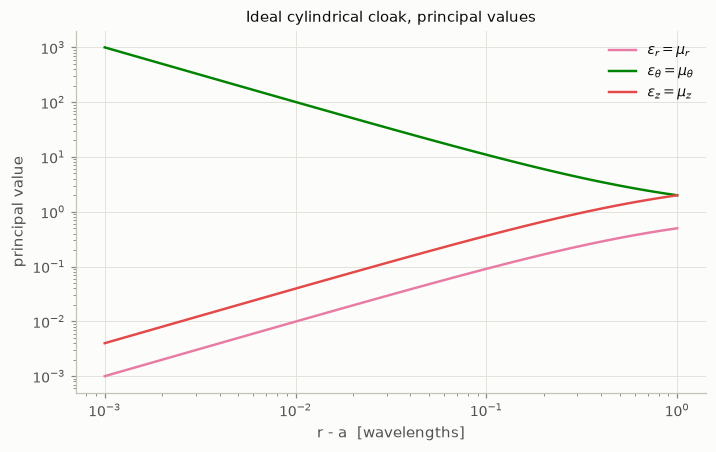

In [4]:
rr = np.logspace(-3, 0, 120)                                   # r - a
pts = jnp.stack([jnp.array(b * rr / (b - a)), jnp.zeros(rr.size), jnp.zeros(rr.size)], axis=1)   # virtual points on the x axis
eps_axis = np.array(jax.vmap(lambda x: medium_from_map(cyl_map, x))(pts))                        # diagonal there: (r, theta, z)
fig, ax = plt.subplots()
for i, (lab, col) in enumerate((("$\\varepsilon_r=\\mu_r$", CAT[4]), ("$\\varepsilon_\\theta=\\mu_\\theta$", CAT[5]), ("$\\varepsilon_z=\\mu_z$", CAT[7]))):
    ax.loglog(rr, eps_axis[:, i, i], color=col, label=lab)
ax.set(xlabel="r - a  [wavelengths]", ylabel="principal value", title="Ideal cylindrical cloak, principal values")
ax.legend()
plt.show()

At the lining $r=a$ the azimuthal value diverges while the radial and the $z$ values vanish, so the product of the three tends to zero, as (33.5) requires of any such map (CLAIMS.md H4). Values below one require dispersive media, which limits the bandwidth (5(d)).

### The 2-D reduction used below

For an in-plane map ($z$ untouched) and $E=E_z(x,y)\hat z$, only the $2\times2$ in-plane block $\mu_t$ of $\mu$ and $\varepsilon_{zz}$ enter. With $e^{-i\omega t}$, Faraday's law gives $H_t=(i\omega\mu_0)^{-1}\mu_t^{-1}J\nabla E_z$, where $J\nabla E_z=(\partial_yE_z,-\partial_xE_z)$. Then $(\nabla\times H)_z=\nabla\!\cdot(JH_t)$ and, for a symmetric $2\times2$ matrix, $J\mu_t^{-1}J=-\mu_t/\det\mu_t$. Ampère's law $(\nabla\times H)_z=-i\omega\varepsilon_0\varepsilon_{zz}E_z$ becomes

$$\nabla\!\cdot\!\big(A\nabla E_z\big)+k_0^2\,\varepsilon_{zz}E_z=0,\qquad A=\frac{\mu_t}{\det\mu_t}=\frac{\Lambda_t\Lambda_t^{T}}{\det\Lambda_t},\qquad \varepsilon_{zz}=\frac1{\det\Lambda_t}.$$

(For $\mu_t=\Lambda_t\Lambda_t^T/\det\Lambda_t$ one has $\det\mu_t=1$, so $A=\mu_t$.) In polar components $A=\mathrm{diag}(1/\mu_\theta,\,1/\mu_r)$.

## 2. The exact field

Because $z$ is untouched, the pulled-back scalar is simply $E_z(x)=E_z'(x'(x))$ for $a<r<b$, the unperturbed field outside, and zero inside the hole. For a plane wave $E'_z=e^{ik_0x'}$ the rays are the images of the lines $y'=\text{const}$. For a line source at $x_s=(-3,\,0.8)$, outside the cloak, $E'_z=\tfrac i4H_0(k_0|x'-x_s|)$. Before plotting, we verify with autodiff that the mapped plane wave solves the anisotropic equation at random points of the shell, building $A$ and $\varepsilon_{zz}$ from the Jacobian of the inverse map.

In [5]:
def g_inv(x):
    """Physical point in the shell -> virtual point (inverse of the radial map)."""
    r = jnp.sqrt(x[0] ** 2 + x[1] ** 2)
    return x * (b * (r - a) / (b - a)) / r


def A_and_epsz(x):
    Lam = jnp.linalg.inv(jax.jacfwd(g_inv)(x))                  # Lambda = dx/dx' = (dx'/dx)^-1
    d = jnp.linalg.det(Lam)
    return Lam @ Lam.T / d, 1.0 / d


E_plane = lambda x: jnp.exp(1j * K0 * g_inv(x)[0])


def wave_equation_terms(x):
    flux = lambda y: A_and_epsz(y)[0] @ jax.jacfwd(E_plane)(y)    # A grad E, complex
    return jnp.trace(jax.jacfwd(flux)(x)), K0**2 * A_and_epsz(x)[1] * E_plane(x)


rng = np.random.default_rng(2)
rad, ang = rng.uniform(a + 0.05, b, 50), rng.uniform(0, 2 * np.pi, 50)
xs = jnp.array(np.stack([rad * np.cos(ang), rad * np.sin(ang)], axis=1))
div_term, eps_term = jax.vmap(wave_equation_terms)(xs)
rel_res = np.abs(np.array(div_term + eps_term)) / (np.abs(np.array(div_term)) + np.abs(np.array(eps_term)))
# tolerance 1e-8 from the brief; the autodiff derivatives are exact, so only rounding (~1e-13) is expected
check("plane wave: max relative residual of div(A grad E) + k0^2 eps_zz E", rel_res.max(), 1e-8)
epsz_formula = (b / (b - a)) ** 2 * (rad - a) / rad
check("eps_zz from the inverse-map Jacobian vs closed form, max rel. error", np.max(np.abs(np.array(jax.vmap(A_and_epsz)(xs)[1]) / epsz_formula - 1)), 1e-12)

PASS  plane wave: max relative residual of div(A grad E) + k0^2 eps_zz E: got 1.35412e-15, target 0, |diff| 1.35e-15 <= 1e-08
PASS  eps_zz from the inverse-map Jacobian vs closed form, max rel. error: got 6.66134e-16, target 0, |diff| 6.66e-16 <= 1e-12


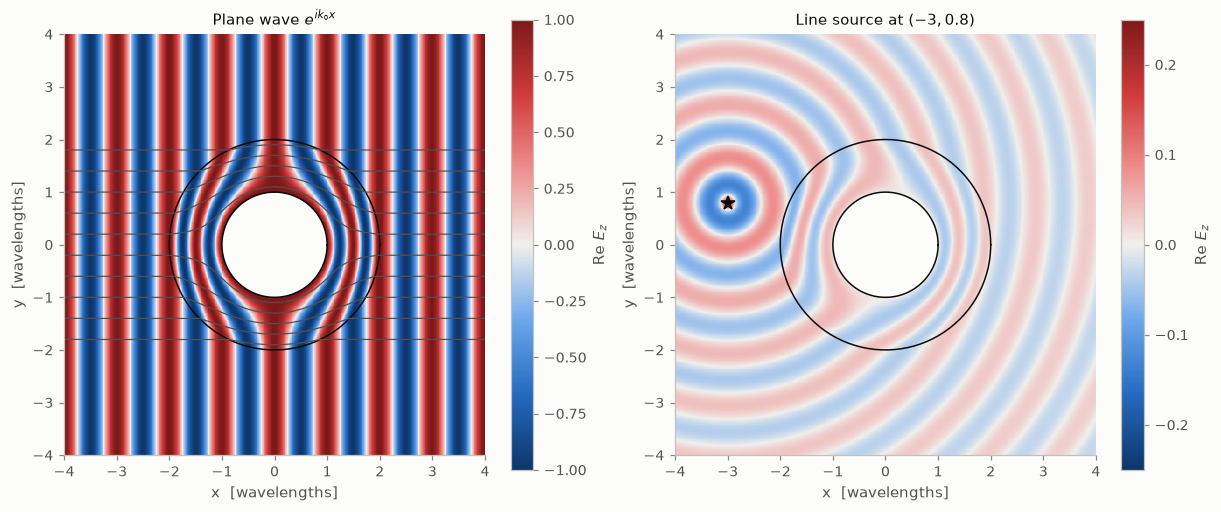

In [6]:
xs_src = np.array([-3.0, 0.8])


def to_virtual(X, Y):
    """Physical grid -> virtual coordinates (identity outside the cloak, NaN inside the hole)."""
    R = np.hypot(X, Y)
    Rp = np.where(R < b, b * (R - a) / (b - a), R)
    sc = Rp / np.where(R > 0, R, 1.0)
    return np.where(R < a, np.nan, X * sc), np.where(R < a, np.nan, Y * sc)


def forward_map(xp, yp):
    rp = np.hypot(xp, yp)
    r = np.where(rp < b, a + (b - a) * rp / b, rp)
    return r / rp * xp, r / rp * yp


L = 4.0
g = np.linspace(-L, L, 481)
X, Y = np.meshgrid(g, g)
Xv, Yv = to_virtual(X, Y)
fields = {"Plane wave $e^{ik_0x}$": (np.exp(1j * K0 * Xv).real, 1.0),
          "Line source at $(-3, 0.8)$": ((0.25j * hankel1(0, K0 * np.hypot(Xv - xs_src[0], Yv - xs_src[1]))).real, 0.25)}
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
th = np.linspace(0, 2 * np.pi, 200)
t_ray = np.linspace(-L - 1, L + 1, 3000)
for ax, (title, (field, vmax)) in zip(axes, fields.items()):
    im = ax.imshow(field, extent=(-L, L, -L, L), cmap=DIV, vmin=-vmax, vmax=vmax)
    for rad_ in (a, b):
        ax.plot(rad_ * np.cos(th), rad_ * np.sin(th), color=INK, lw=1)
    ax.set(xlabel="x  [wavelengths]", ylabel="y  [wavelengths]", title=title, xlim=(-L, L), ylim=(-L, L))
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label="Re $E_z$")
    if title.startswith("Plane"):
        for c in np.linspace(-1.8, 1.8, 10):                       # images of the lines y' = c
            rx, ry = forward_map(t_ray, np.full_like(t_ray, c))
            ax.plot(rx, ry, color=INK2, lw=0.8)
    else:
        ax.plot(*xs_src, marker="*", color=INK, ms=9, ls="none")
plt.show()

The rays bend around the hole and leave on their original lines; outside the shell the field is unperturbed. No solver is involved here, so the partial-wave solver of the next section is an independent test.

## 3. Partial waves for radially varying anisotropic cylinders

With $E_z=\sum_m e_m(r)e^{im\theta}$ the equation of section 1 becomes, for $A=\mathrm{diag}(1/\mu_\theta,1/\mu_r)$,

$$\frac1r\frac{d}{dr}\Big(\frac{r}{\mu_\theta}\frac{de_m}{dr}\Big)-\frac{m^2}{\mu_r r^2}e_m+k_0^2\varepsilon_z e_m=0 .$$

With $F=(r/\mu_\theta)\,de/dr$ (proportional to $H_\theta$, hence continuous across interfaces together with $e$) this is the first-order system

$$\frac{de}{dr}=\frac{\mu_\theta}{r}F,\qquad \frac{dF}{dr}=\Big(\frac{m^2}{\mu_r r}-k_0^2\varepsilon_z r\Big)e .$$

Outside, for an incident plane wave $e^{ik_0x}=\sum_m i^mJ_m(k_0r)e^{im\theta}$ we write $e_m=i^m\,[J_m(k_0r)+s_mH_m(k_0r)]$, and drop the factor $i^m$. Matching $(e,F)$ from the interior at $r=b$ gives (with $x=k_0b$ and primes denoting derivatives with respect to the argument)

$$s_m=-\frac{F_bJ_m(x)-e_b\,xJ_m'(x)}{F_bH_m(x)-e_b\,xH_m'(x)}.$$

The far field is $E^{sc}\to\sqrt{2/(\pi k_0r)}\,e^{i(k_0r-\pi/4)}\sum_m s_me^{im\theta}$. The scattering width (scattered power per length over incident intensity) is the angular integral of $|E^{sc}|^2r$; the extinction width follows from the optical theorem:

$$\sigma_{sca}=\frac4{k_0}\sum_{m=-\infty}^{\infty}|s_m|^2,\qquad \sigma_{ext}=-\frac4{k_0}\sum_{m}\mathrm{Re}\,s_m,\qquad \sigma_{abs}=\sigma_{ext}-\sigma_{sca}.$$

Since $s_{-m}=s_m$ the sums fold onto $m\ge0$. For lossless media $\sigma_{abs}=0$, equivalently $|1+2s_m|=1$ for every $m$.

**Implementation.** The medium enters as callables of $(r,\rho)$, with $\rho=r-r_0$ passed separately to keep full precision when it is $10^{-12}$. We integrate in $t=\ln\rho$ with `solve_ivp` (DOP853, rtol $10^{-12}$), all $m$ at once, renormalizing every 1.5 units of $t$ (the system is linear and $s_m$ depends only on $e_b/F_b$). Inner conditions: `pec` ($e=0$, $F=1$), `pmc` ($e=1$, $F=0$) or a dielectric core of permittivity $\varepsilon_c$ ($e=J_m(k_0n_cr_{in})$, $F=r_{in}k_0n_cJ_m'(k_0n_cr_{in})$). Layers and a complex detour (5(d)) are options.

In [7]:
def match_s(Eb, Fb, rb, k=K0):
    """Exterior matching at r = b for the folded partial waves m = 0..M-1."""
    m = np.arange(Eb.size); x = k * rb
    J, dJ, H, dH = jv(m, x), jvp(m, x), hankel1(m, x), h1vp(m, x)
    return -(Fb * J - Eb * x * dJ) / (Fb * H - Eb * x * dH)


def widths(s, k=K0):
    """(sigma_sca, sigma_abs, sigma_ext) from folded coefficients s_0..s_M."""
    w = np.where(np.arange(s.size) == 0, 1.0, 2.0)
    sca, ext = 4 / k * np.sum(w * np.abs(s) ** 2), -4 / k * np.sum(w * s.real)
    return sca, ext - sca, ext


def bare_pec(m_max, rad=a, k=K0):
    m = np.arange(m_max + 1)
    return -jv(m, k * rad) / hankel1(m, k * rad)


def scatter_coeffs(mu_r, mu_theta, eps_z, r_in, b, inner, m_max, *, r0=0.0, rho_in=None, eps_c=None, k=K0,
                   layers=None, contour=None, dense=False):
    """s_m, m = 0..m_max, by integrating (E, F) in t = ln(r - r0) from r_in to b. Media: callables (r, rho)."""
    m = np.arange(m_max + 1); M = m.size; m2 = m.astype(float) ** 2
    if inner == "pec":
        y = np.concatenate([np.zeros(M), np.ones(M)]).astype(complex)
    elif inner == "pmc":
        y = np.concatenate([np.ones(M), np.zeros(M)]).astype(complex)
    else:
        kn = k * np.sqrt(complex(eps_c))
        y = np.concatenate([jv(m, kn * r_in), r_in * kn * jvp(m, kn * r_in)]).astype(complex)
    if layers is None:
        segs = [(r_in, b, mu_r, mu_theta, eps_z)]
    else:                                                       # layers: outer radii and constant (mu_r, mu_theta, eps_z)
        edges = np.concatenate([[r_in], layers["edges"]])
        segs = [(edges[i], edges[i + 1]) + tuple((lambda r, p, v=layers[key][i]: v) for key in ("mu_r", "mu_theta", "eps_z"))
                for i in range(len(edges) - 1)]
    pieces, cum = [], np.zeros(M)                               # cum: log of the accumulated renormalization
    for (rl, rh, fmr, fmt, fez) in segs:
        tl = np.log(rho_in if (rho_in is not None and rl == r_in) else rl - r0); th = np.log(rh - r0)
        ts = np.linspace(tl, th, max(1, int(np.ceil((th - tl) / 1.5))) + 1)
        def rhs(t, y, fmr=fmr, fmt=fmt, fez=fez):
            rho = np.exp(t); r = r0 + rho; dr = rho
            if contour is not None:
                r, rho, dr = contour(t)                         # complex detour: r(t), rho(t), dr/dt
            return np.concatenate([dr * fmt(r, rho) / r * y[M:], dr * (m2 / (fmr(r, rho) * r) - k * k * fez(r, rho) * r) * y[:M]])
        for j in range(len(ts) - 1):
            sol = solve_ivp(rhs, (ts[j], ts[j + 1]), y, method="DOP853", rtol=1e-12, atol=1e-14, dense_output=dense)
            yb = sol.y[:, -1]; sc = np.maximum(np.abs(yb[:M]), np.abs(yb[M:])); sc = np.where(sc > 0, sc, 1.0)
            pieces.append((ts[j], ts[j + 1], sol, cum.copy())); y = yb / np.concatenate([sc, sc]); cum = cum + np.log(sc)
    s = match_s(y[:M], y[M:], b, k)
    return (s, dict(pieces=pieces, cum=cum, Eb=y[:M], r0=r0, M=M)) if dense else s


def interior_ratio(dense, r):
    """e_m(r)/e_m(b) for all m, shape (M, len(r)), from the dense output of scatter_coeffs(..., dense=True)."""
    t = np.log(r - dense["r0"]); out = np.zeros((dense["M"], r.size), complex); last = dense["pieces"][-1][1]
    for t0, t1, sol, cum0 in dense["pieces"]:
        sel = (t >= t0) & ((t <= t1) if t1 == last else (t < t1))
        if sel.any():
            out[:, sel] = sol.sol(t[sel])[:dense["M"]] * np.exp(cum0 - dense["cum"])[:, None] / dense["Eb"][:, None]
    return out

**Validation.** (a) A PEC cylinder of radius $a$ under a vacuum shell must give $s_m=-J_m(k_0a)/H_m(k_0a)$. (b) A dielectric cylinder with $\varepsilon_c=2.5$ and radius $a$ under a vacuum shell must reproduce the Mie coefficients of `bayes_scatter.mie`. (c) Lossless media must satisfy $|1+2s_m|=1$.

In [8]:
m_max = int(np.ceil(K0 * b)) + 15
vac = lambda r, p: 1.0
s_pec = scatter_coeffs(vac, vac, vac, a, b, "pec", m_max)
s_die = scatter_coeffs(vac, vac, vac, a, b, "diel", m_max, eps_c=2.5)
# tolerances tightened from the brief's 1e-9 to 1e-12: DOP853 at rtol 1e-12 delivers about 1e-14 in s_m
check("(a) PEC under vacuum shell vs -J/H: max |ds_m|", np.abs(s_pec - bare_pec(m_max)).max(), 1e-12)
check("(b) dielectric core vs bayes_scatter.mie: max |ds_m|", np.abs(s_die - mie_coefficients(m_max, a, 2.5, K0)).max(), 1e-12)
check("(c) |1 + 2 s_m| = 1, PEC", np.abs(np.abs(1 + 2 * s_pec) - 1).max(), 1e-8)
check("(c) |1 + 2 s_m| = 1, dielectric", np.abs(np.abs(1 + 2 * s_die) - 1).max(), 1e-8)
sw = widths(s_die)
check("(c) dielectric: sigma_abs / sigma_sca", sw[1] / sw[0], 1e-8)

PASS  (a) PEC under vacuum shell vs -J/H: max |ds_m|: got 1.95414e-15, target 0, |diff| 1.95e-15 <= 1e-12
PASS  (b) dielectric core vs bayes_scatter.mie: max |ds_m|: got 8.86099e-15, target 0, |diff| 8.86e-15 <= 1e-12
PASS  (c) |1 + 2 s_m| = 1, PEC: got 9.99201e-16, target 0, |diff| 9.99e-16 <= 1e-08
PASS  (c) |1 + 2 s_m| = 1, dielectric: got 7.77156e-16, target 0, |diff| 7.77e-16 <= 1e-08
PASS  (c) dielectric: sigma_abs / sigma_sca: got 6.02717e-16, target 0, |diff| 6.03e-16 <= 1e-08


## 4. The ideal cloak is a shrinking device

A physical cloak cannot reach $r=a$ exactly: truncate it at $r_{in}=a+\delta$ and put a wall or a core there. Inside the ideal cloak, with $r'=b(r-a)/(b-a)$, the system above becomes Bessel's equation, because $F=r'\,de/dr'$ and

$$r'\frac{d}{dr'}\Big(r'\frac{de}{dr'}\Big)+(k_0^2r'^2-m^2)\,e=0 .$$

So $e_m=\alpha J_m(k_0r')+\beta Y_m(k_0r')$ throughout the shell, and the exterior only sees a virtual-space object whose surface is at $\delta'=b\delta/(b-a)$ (the factor is the compression of the map at the lining). A PEC wall at $r=a+\delta$ therefore scatters exactly like a bare PEC wire of radius $\delta'$: $s_m=-J_m(k_0\delta')/H_m(k_0\delta')$. A PMC wall gives $-J_m'(k_0\delta')/H_m'(k_0\delta')$, and a dielectric core is a general impedance $F/e$ at $r'=\delta'$ fixing $(\alpha,\beta)$ through the Wronskian $J_mY_m'-J_m'Y_m=2/(\pi x)$.

**Which solver is used where.** The ODE reproduces the PEC closed form for the four $\delta$ below. For the sweep to $\delta=10^{-12}a$ we use the analytic transfer (`ideal_coeffs`), which evaluates the small ratio $\beta/\alpha$ directly: for a PMC lining $s_m\propto\delta^2$ falls below the absolute accuracy of the ODE at small $\delta$ (last column of the comparison table).

In [9]:
sig_bare = widths(bare_pec(m_max))[0]
ideal = (lambda r, p: p / r, lambda r, p: r / p, lambda r, p: (b / (b - a)) ** 2 * p / r)   # mu_r, mu_theta, eps_z of the ideal cloak


def ideal_coeffs(delta, inner, m_max, eps_c=None, k=K0):
    """Exact s_m of the ideal cloak with a lining at r = a + delta (no cancellation).

    Interior e = alpha J_m(k r') + beta Y_m(k r'), F = r' de/dr'. Outside, J + s H has the same Cauchy data at r = b, so
    1 + s = c alpha and i s = c beta, hence s = q/(i - q) with q = beta/alpha fixed by the lining at r' = delta'."""
    m = np.arange(m_max + 1); xd = k * b * delta / (b - a)
    with np.errstate(all="ignore"):
        Jd, Yd, dJd, dYd = jv(m, xd), yv(m, xd), jvp(m, xd), yvp(m, xd)
        if inner == "pec":
            q = -Jd / Yd
        elif inner == "pmc":
            q = -dJd / dYd
        else:
            kn, rin = k * np.sqrt(eps_c), a + delta
            e0, f0 = jv(m, kn * rin), rin * kn * jvp(m, kn * rin)    # core data: e and F at r = a + delta
            q = (f0 / xd * Jd - e0 * dJd) / (e0 * dYd - f0 / xd * Yd)
        s = q / (1j - q)
    return np.where(np.isfinite(s), s, 0.0)                         # terms beyond float range (m >= 1, tiny delta) are zero


print("PEC wall at a + delta, cloaked, against a bare PEC wire of radius delta' = b delta/(b - a):")
print(f"{'delta/a':>9} {'sigma/sigma_bare (ODE)':>24} {'(wire formula)':>16} {'rel. diff':>10}")
for e in (1, 2, 3, 4):
    d = 10.0 ** -e
    s_ode = scatter_coeffs(*ideal, a + d, b, "pec", m_max, r0=a, rho_in=d)
    wire = bare_pec(m_max, b * d / (b - a))                      # -J_m(k delta')/H_m(k delta')
    r1, r2 = widths(s_ode)[0], widths(wire)[0]
    print(f"{d:9.0e} {r1 / sig_bare:24.6e} {r2 / sig_bare:16.6e} {abs(r1 / r2 - 1):10.1e}")
    check(f"cloaked PEC core, delta = {d:.0e}: relative error of sigma", abs(r1 / r2 - 1), 1e-9)   # brief asks 1e-6; the ODE delivers ~1e-14, 1e-9 leaves margin

PEC wall at a + delta, cloaked, against a bare PEC wire of radius delta' = b delta/(b - a):
  delta/a   sigma/sigma_bare (ODE)   (wire formula)  rel. diff
    1e-01             2.469084e-01     2.469084e-01    1.2e-15
PASS  cloaked PEC core, delta = 1e-01: relative error of sigma: got 1.22125e-15, target 0, |diff| 1.22e-15 <= 1e-09
    1e-02             4.736997e-02     4.736997e-02    1.3e-15
PASS  cloaked PEC core, delta = 1e-02: relative error of sigma: got 1.33227e-15, target 0, |diff| 1.33e-15 <= 1e-09
    1e-03             1.514153e-02     1.514153e-02    4.8e-15
PASS  cloaked PEC core, delta = 1e-03: relative error of sigma: got 4.77396e-15, target 0, |diff| 4.77e-15 <= 1e-09


    1e-04             7.050821e-03     7.050821e-03    1.4e-14
PASS  cloaked PEC core, delta = 1e-04: relative error of sigma: got 1.35447e-14, target 0, |diff| 1.35e-14 <= 1e-09


In [10]:
linings = {"PEC wall": ("pec", None), "PMC wall": ("pmc", None), "dielectric core (eps_c = 4)": ("diel", 4.0)}
decades = np.arange(1, 13)
table = {}
for name, (inner, ec) in linings.items():
    rows = []
    for e in decades:
        d = 10.0 ** -e
        s_ode = scatter_coeffs(*ideal, a + d, b, inner, m_max, r0=a, rho_in=d, eps_c=ec)
        s_ana = ideal_coeffs(d, inner, m_max, eps_c=ec)
        rows.append((widths(s_ode)[0] / sig_bare, widths(s_ana)[0] / sig_bare, np.abs(s_ode - s_ana).max()))
    table[name] = np.array(rows)
print(f"sigma/sigma_bare, analytic transfer (A) and ODE (O); last column of each block: max_m |s_ode - s_ana|")
print(f"{'delta/a':>8} " + " | ".join(f"{n[:18]:^37}" for n in linings))
for i, e in enumerate(decades):
    print(f"{10.0 ** -e:8.0e} " + " | ".join(f"{table[n][i, 1]:11.3e} {table[n][i, 0]:11.3e} {table[n][i, 2]:9.1e}" for n in linings))
# the ODE is accurate to ~1e-15 in s_m (rtol 1e-12, renormalized steps), whatever the lining and delta
for n in linings:
    check(f"ODE vs analytic transfer, {n}: max |ds_m| over all delta", table[n][:, 2].max(), 1e-12)
for n in ("PEC wall", "dielectric core (eps_c = 4)"):
    check(f"ODE vs analytic transfer, {n}: max relative sigma error", np.max(np.abs(table[n][:, 0] / table[n][:, 1] - 1)), 1e-9)

sigma/sigma_bare, analytic transfer (A) and ODE (O); last column of each block: max_m |s_ode - s_ana|
 delta/a               PEC wall                |               PMC wall                |          dielectric core (e          
   1e-01   2.469e-01   2.469e-01   2.3e-15 |   9.643e-02   9.643e-02   2.3e-15 |   2.188e-01   2.188e-01   1.5e-15
   1e-02   4.737e-02   4.737e-02   9.8e-16 |   6.381e-05   6.381e-05   1.3e-15 |   4.449e-02   4.449e-02   8.9e-16
   1e-03   1.514e-02   1.514e-02   2.3e-15 |   6.415e-09   6.415e-09   2.8e-15 |   1.465e-02   1.465e-02   1.6e-15
   1e-04   7.051e-03   7.051e-03   1.6e-15 |   6.414e-13   6.414e-13   1.6e-15 |   6.893e-03   6.893e-03   1.9e-15
   1e-05   4.024e-03   4.024e-03   2.5e-15 |   6.414e-17   6.414e-17   1.2e-15 |   3.955e-03   3.955e-03   2.1e-15
   1e-06   2.590e-03   2.590e-03   1.8e-15 |   6.414e-21   6.414e-21   1.9e-15 |   2.554e-03   2.554e-03   2.9e-15
   1e-07   1.803e-03   1.803e-03   1.1e-15 |   6.414e-25   6.408e-25   1.1e-15 | 

**Main result.** The figure plots $\sigma/\sigma_{bare}$ (bare PEC cylinder of radius $a$) against $\delta/a$ for the three linings; circles are the ODE, lines the analytic transfer. The expectation to test: for PEC and dielectric linings the $m=0$ term of $-J_0(x)/H_0(x)$, $x=k_0\delta'$, behaves like $\big[1+\tfrac4{\pi^2}(\ln\tfrac x2+\gamma_E)^2\big]^{-1}$, i.e. $\sigma\sim1/\ln^2(k_0\delta')$, which is a very slow (logarithmic) decay; for a PMC lining $s_m\propto x^2$ for every $m$, so $\sigma\propto\delta^4$. The narrow dip of the dielectric curve near $\delta/a\sim0.06$, where the core is no longer small, is explained below the figure.

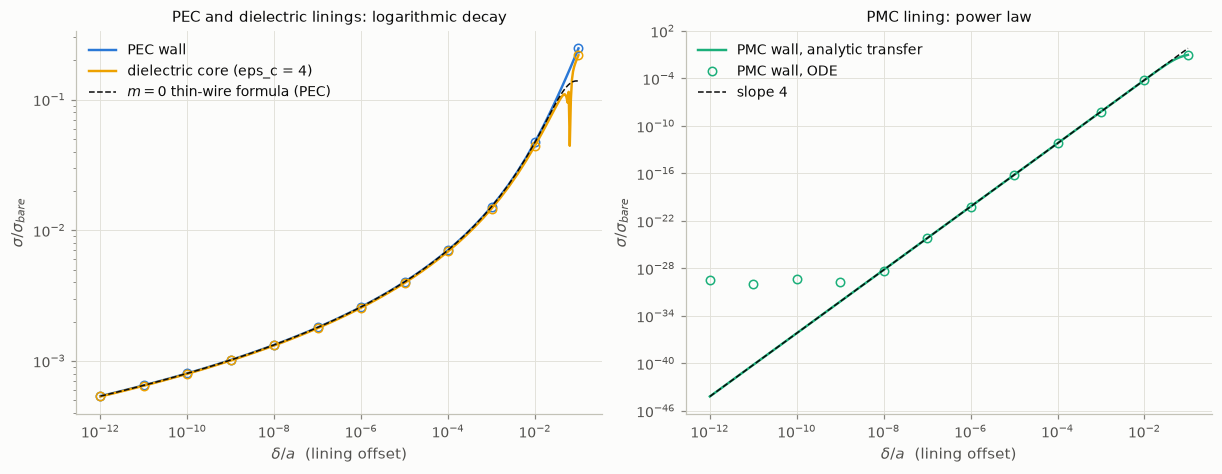

sigma / sigma_bare at selected offsets (analytic transfer)
 delta/a                     PEC wall                     PMC wall  dielectric core (eps_c = 4)
   1e-03                   1.5142e-02                   6.4149e-09                   1.4654e-02
   1e-06                   2.5897e-03                   6.4144e-21                   2.5539e-03
   1e-12                   5.3731e-04                   6.4144e-45                   5.3388e-04
PEC lining: sigma(delta/a = 1e-3) / sigma(delta/a = 1e-12) = 28.2;   PMC lining: 1.0e+36
dielectric dip at delta/a = 0.0624; the core's m = 0 impedance F/e vanishes (J_1(k0 n_c (a + delta)) = 0) at delta/a = 0.0603
PASS  dielectric dip sits at the zero of the core's m = 0 impedance (relative offset): got 0.0355805, target 0, |diff| 3.56e-02 <= 6e-02
PMC log-log slope: ODE over 1e-6..1e-3: 4.0000; analytic over 1e-12..1e-4: 4.0000
PASS  PMC slope from the ODE (delta 1e-6..1e-3): got 4.00001, target 4, |diff| 6.86e-06 <= 5e-02
PASS  PMC slope from the a

In [11]:
dgrid = np.unique(np.concatenate([np.logspace(-12, -2, 51), np.logspace(-2, -1, 41)]))   # dense above 1e-2: resolves the core's own Mie resonance
sweep = {n: np.array([widths(ideal_coeffs(d, inner, m_max, eps_c=ec))[0] for d in dgrid]) / sig_bare for n, (inner, ec) in linings.items()}
colors = {"PEC wall": PEC_C, "PMC wall": PMC_C, "dielectric core (eps_c = 4)": DIEL_C}
xd_ = K0 * b * dgrid / (b - a)
asym = 4 / K0 / (1 + 4 / np.pi**2 * (np.log(xd_ / 2) + np.euler_gamma) ** 2) / sig_bare      # m = 0 term of a thin PEC wire
d_ode = np.logspace(-6, -3, 13)                                                                # PMC slope from the ODE alone
sig_ode = np.array([widths(scatter_coeffs(*ideal, a + d, b, "pmc", m_max, r0=a, rho_in=d))[0] for d in d_ode])
slope_ode = np.polyfit(np.log(d_ode), np.log(sig_ode), 1)[0]
mask = dgrid <= 1e-4
slope_ana = np.polyfit(np.log(dgrid[mask]), np.log(sweep["PMC wall"][mask]), 1)[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for n in ("PEC wall", "dielectric core (eps_c = 4)"):
    ax1.loglog(dgrid, sweep[n], color=colors[n], label=n)
    ax1.loglog(10.0 ** -decades, table[n][:, 0], ls="none", marker="o", mfc="none", color=colors[n])
ax1.loglog(dgrid, asym, color=INK, ls="--", lw=1, label="$m=0$ thin-wire formula (PEC)")
ax1.set(xlabel="$\\delta/a$  (lining offset)", ylabel="$\\sigma/\\sigma_{bare}$", title="PEC and dielectric linings: logarithmic decay")
ax1.legend()
ax2.loglog(dgrid, sweep["PMC wall"], color=PMC_C, label="PMC wall, analytic transfer")
ax2.loglog(10.0 ** -decades, table["PMC wall"][:, 0], ls="none", marker="o", mfc="none", color=PMC_C, label="PMC wall, ODE")
ax2.loglog(dgrid, sweep["PMC wall"][0] * (dgrid / dgrid[0]) ** 4, color=INK, ls="--", lw=1, label="slope 4")
ax2.set(xlabel="$\\delta/a$  (lining offset)", ylabel="$\\sigma/\\sigma_{bare}$", title="PMC lining: power law")
ax2.legend()
plt.show()

print("sigma / sigma_bare at selected offsets (analytic transfer)")
print(f"{'delta/a':>8} " + " ".join(f"{n:>28}" for n in linings))
for e in (3, 6, 12):
    print(f"{10.0 ** -e:8.0e} " + " ".join(f"{table[n][e - 1, 1]:28.4e}" for n in linings))
print(f"PEC lining: sigma(delta/a = 1e-3) / sigma(delta/a = 1e-12) = {table['PEC wall'][2, 1] / table['PEC wall'][11, 1]:.1f};   PMC lining: {table['PMC wall'][2, 1] / table['PMC wall'][11, 1]:.1e}")
dd = np.linspace(0.03, 0.09, 6001)
dip = dd[np.argmin([widths(ideal_coeffs(d, "diel", m_max, eps_c=4.0))[0] for d in dd])]
j1 = brentq(lambda t: jv(1, t), 12.0, 14.0)                      # first zero of J_1 above 12: F_0 = r de/dr of the core's m = 0 field vanishes at k0 n_c r_in = j1
d_zero = j1 / (K0 * 2.0) - a
print(f"dielectric dip at delta/a = {dip:.4f}; the core's m = 0 impedance F/e vanishes (J_1(k0 n_c (a + delta)) = 0) at delta/a = {d_zero:.4f}")
check("dielectric dip sits at the zero of the core's m = 0 impedance (relative offset)", dip / d_zero - 1, 0.06)
print(f"PMC log-log slope: ODE over 1e-6..1e-3: {slope_ode:.4f}; analytic over 1e-12..1e-4: {slope_ana:.4f}")
# tolerances: 0.05 from the brief; corrections to the pure power law are O((k0 delta')^2 ln) <= a few 1e-3 at delta = 1e-3
check("PMC slope from the ODE (delta 1e-6..1e-3)", slope_ode, 0.05, 4.0)
check("PMC slope from the analytic transfer (delta 1e-12..1e-4)", slope_ana, 0.05, 4.0)
# the dropped terms are m >= 1 (O(x^2 ln x) relative) and J_0(x) - 1 = O(x^2): 1e-6 is generous at delta = 1e-12
check("PEC at delta = 1e-12: exact vs m = 0 thin-wire formula, relative", sweep["PEC wall"][0] / asym[0] - 1, 1e-6)

**The dip.** Near $\delta/a\approx0.06$ the core's $m=0$ field has $J_1(k_0n_c(a+\delta))=0$, i.e. its impedance $F/e$ vanishes, so for $m=0$ the core acts as the magnetic wall of the next paragraph. The printed location agrees; it is not a Mie resonance of the core.

**Why.** For $m=0$ the ideal field is $J_0(k_0r')$, which equals one, not zero, at the lining $r'=0$. A PEC wall at $r'=\delta'$ forces $e=0$ there, so the field must fall from order one to zero across a logarithmically wide layer, from $r'\sim\delta'$ up to the wavelength scale; in two dimensions the only way a solution of Bessel's equation does that is through the logarithm of $Y_0$, with an amplitude $\sim1/\ln(k_0\delta')$ that shrinks very slowly. A dielectric core imposes an impedance $F/e$ of order one at $r'=\delta'$ (the core has size $a$, not $\delta'$), so it behaves like the PEC case. A PMC wall (a magnetic wall for $E_z$) imposes $de/dr'=0$, which $J_0$ satisfies at the origin up to $O(\delta'^2)$, so nothing needs to be repaired. Any lining with $F/e=O(\delta'^2)$ would do the same.

**Connection to CLAIMS.md H4.** The book's mapped cylindrical field has $E_z$ equal to the nonzero virtual value at $r'=0$ on the whole lining while $H_\theta\to0$; no source-free interior field has these Cauchy data in general, so the ideal two-dimensional cloak needs a *magnetic* surface current on its lining ($E_z$ jumps to zero across it); a PEC wall carries only an electric one. The sweep makes this quantitative: a PEC or dielectric lining leaves a residue that decays only like $1/\ln^2$, while a lining compatible with $de/dr'=0$ gives a power law. The polarization-independent version is the soft-and-hard-surface lining ($E_\theta=H_\theta=0$) of Greenleaf, Kurylev, Lassas and Uhlmann (2007); for $E_z$ it reduces to the magnetic wall used here, so the "PMC wall" of this notebook is polarization specific, not an all-components PMC.

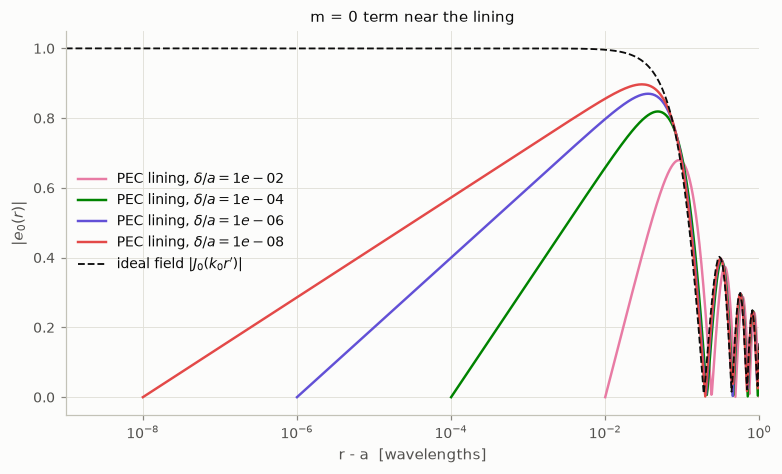

In [12]:
# (the profiles below use the closed-form interior solution, not the ODE dense output)
def m0_profile(delta, rho, k=K0):
    """Closed-form interior solution (not the ODE): |e_0(r)| for a PEC lining at a + delta, normalized to the incident plane-wave convention e_0 = J_0 + s_0 H_0 at r = b."""
    xd, rp, xb = k * b * delta / (b - a), b * rho / (b - a), k * b
    al, be = yv(0, xd), -jv(0, xd)
    inner_field = lambda x: al * jv(0, x) + be * yv(0, x)
    s0 = ideal_coeffs(delta, "pec", 0)[0]
    return np.abs(inner_field(k * rp) / inner_field(xb) * (jv(0, xb) + s0 * hankel1(0, xb)))


fig, ax = plt.subplots(figsize=(7, 4.2))
deltas = (1e-2, 1e-4, 1e-6, 1e-8)
for d, col in zip(deltas, (CAT[4], CAT[5], CAT[6], CAT[7])):
    rho = np.logspace(np.log10(d), 0, 400)
    ax.semilogx(rho, m0_profile(d, rho), color=col, label=f"PEC lining, $\\delta/a={d:.0e}$")
rho = np.logspace(-9, 0, 400)
ax.semilogx(rho, np.abs(jv(0, K0 * b * rho / (b - a))), color=INK, ls="--", lw=1.2, label="ideal field $|J_0(k_0r')|$")
ax.set(xlabel="r - a  [wavelengths]", ylabel="$|e_0(r)|$", title="m = 0 term near the lining", xlim=(1e-9, 1))
ax.legend()
plt.show()

## 5. Imperfect cloaks

Baseline: the ideal medium with a PMC lining at $\delta=10^{-3}a$, the "near-ideal cloak". The PMC lining is the favorable choice of section 4; the reduced cloak has a PEC core, so the ideal medium with the same PEC lining is printed beside it for a like-for-like comparison.

### (a) Reduced parameters

The first microwave cloak (Schurig et al., 2006) used $\mu_r=\big(\tfrac{r-a}r\big)^2$, $\mu_\theta=1$, $\varepsilon_z=\big(\tfrac b{b-a}\big)^2$ around a PEC core. Since TM waves only see the products $\mu_\theta\varepsilon_z$ and $\mu_r\varepsilon_z$ in the dispersion relation, a medium with the same two products has the same rays (the eikonal equation). The reduced set meets this condition, but the impedance relevant to radial propagation, $\sqrt{\mu_\theta/\varepsilon_z}$, is no longer matched at $r=b$, so the outer surface reflects. That is one cause of the residual. A *matched variant*, $\mu_r=\tfrac b{b-a}\big(\tfrac{r-a}r\big)^2$, $\mu_\theta=\varepsilon_z=\tfrac b{b-a}$, has the same two products and impedance one at $r=b$, and removes it. The other cause is the $m=0$ partial wave: it has no $m^2/\mu_r$ term, so it sees $\mu_\theta$ and $\varepsilon_z$ separately and meets a homogeneous shell of index $b/(b-a)$ whatever $\mu_r$ does. Equal rays do not imply equal scattering, and no reduced set of this kind cloaks $m=0$ (Yan, Ruan and Qiu, 2007); the table below separates the mechanisms through $|s_0|$. A PEC core is used for the reduced cloak because that is the experiment; the value of $\delta$ barely matters, as the printout of $\sigma$ for three truncations shows.

In [13]:
reduced = (lambda r, p: (p / r) ** 2, lambda r, p: 1.0, lambda r, p: (b / (b - a)) ** 2)
r_t = np.linspace(a + 1e-3, b, 400); p_t = r_t - a
mr_i, mt_i, ez_i = (f(r_t, p_t) for f in ideal)
mr_r, mt_r, ez_r = (f(r_t, p_t) * np.ones_like(r_t) for f in reduced)   # mu_theta is a constant: broadcast
check("mu_theta eps_z: reduced vs ideal, max rel. difference", np.max(np.abs(mt_r * ez_r / (mt_i * ez_i) - 1)), 1e-12)   # algebraic identity (a consistency test, not a validation of the solver), rounding only
check("mu_r eps_z: reduced vs ideal, max rel. difference", np.max(np.abs(mr_r * ez_r / (mr_i * ez_i) - 1)), 1e-12)
print(f"radial impedance sqrt(mu_theta/eps_z) at r = b:  ideal {np.sqrt(mt_i[-1] / ez_i[-1]):.4f},  reduced {np.sqrt(mt_r[-1] / ez_r[-1]):.4f}   (vacuum = 1)")
check("ideal cloak is impedance matched at r = b", np.sqrt(mt_i[-1] / ez_i[-1]), 1e-12, 1.0)

delta = 1e-3
m_f = int(np.ceil(K0 * L)) + 15          # the incident plane wave needs m up to k0 r_max, so the field maps use more orders
s_near, d_near = scatter_coeffs(*ideal, a + delta, b, "pmc", m_f, r0=a, rho_in=delta, dense=True)
s_red, d_red = scatter_coeffs(*reduced, a + delta, b, "pec", m_f, r0=a, rho_in=delta, dense=True)
s_bare = bare_pec(m_f)
sC = b / (b - a)                                                         # matched variant: mu_theta = eps_z = b/(b-a), impedance 1 at r = b
matched = (lambda r, p: sC * (p / r) ** 2, lambda r, p: sC, lambda r, p: sC)
s_ipec = scatter_coeffs(*ideal, a + delta, b, "pec", m_f, r0=a, rho_in=delta)      # ideal medium, same PEC lining as the reduced cloak
s_match = scatter_coeffs(*matched, a + delta, b, "pec", m_f, r0=a, rho_in=delta)
print("reduced cloak, PEC core: sigma/sigma_bare for the truncation delta/a = 1e-2, 1e-3, 1e-5:",
      *(f"{widths(scatter_coeffs(*reduced, a + d, b, 'pec', m_max, r0=a, rho_in=d))[0] / sig_bare:.5f}" for d in (1e-2, 1e-3, 1e-5)))
print(f"\n{'object':<44}{'sigma_sca/sigma_bare':>22}{'|s_0|':>10}")
for name, s_ in (("bare PEC cylinder (radius a)", s_bare), ("near-ideal cloak, PMC lining", s_near), ("ideal cloak, PEC lining (same delta)", s_ipec),
                 ("reduced cloak, PEC core", s_red), ("reduced cloak matched at b, PEC core", s_match)):
    print(f"{name:<44}{widths(s_)[0] / sig_bare:22.4e}{abs(s_[0]):10.3f}")
sg = lambda s_: widths(s_)[0]
print(f"reduced / ideal, both with the PEC lining: {sg(s_red) / sg(s_ipec):.1f};  matched reduced / ideal PEC-lined: {sg(s_match) / sg(s_ipec):.1f};  "
      f"share of the reduced sigma removed by matching the impedance: {1 - sg(s_match) / sg(s_red):.2f}")
check("matched variant has the same two products as the ideal medium", np.max(np.abs(np.array([matched[0](r_t, p_t) * matched[2](r_t, p_t) / (mr_i * ez_i), matched[1](r_t, p_t) * matched[2](r_t, p_t) / (mt_i * ez_i)]) - 1)), 1e-12)
check("impedance matching lowers sigma of the reduced cloak (1 = yes)", float(sg(s_match) < sg(s_red)), 0.0, 1.0)
check("... but the m = 0 term stays large with matching: |s_0| > 0.5 (1 = yes)", float(abs(s_match[0]) > 0.5), 0.0, 1.0)
check("... and the reduced cloak is worse than the ideal cloak with the same PEC lining (1 = yes)", float(sg(s_red) > sg(s_ipec)), 0.0, 1.0)

PASS  mu_theta eps_z: reduced vs ideal, max rel. difference: got 2.22045e-16, target 0, |diff| 2.22e-16 <= 1e-12
PASS  mu_r eps_z: reduced vs ideal, max rel. difference: got 0, target 0, |diff| 0.00e+00 <= 1e-12
radial impedance sqrt(mu_theta/eps_z) at r = b:  ideal 1.0000,  reduced 0.5000   (vacuum = 1)
PASS  ideal cloak is impedance matched at r = b: got 1, target 1, |diff| 0.00e+00 <= 1e-12


reduced cloak, PEC core: sigma/sigma_bare for the truncation delta/a = 1e-2, 1e-3, 1e-5: 0.28418 0.27684 0.27597

object                                        sigma_sca/sigma_bare     |s_0|
bare PEC cylinder (radius a)                            1.0000e+00     0.693
near-ideal cloak, PMC lining                            6.4149e-09     0.000
ideal cloak, PEC lining (same delta)                    1.5142e-02     0.330
reduced cloak, PEC core                                 2.7684e-01     0.703
reduced cloak matched at b, PEC core                    8.4469e-02     0.705
reduced / ideal, both with the PEC lining: 18.3;  matched reduced / ideal PEC-lined: 5.6;  share of the reduced sigma removed by matching the impedance: 0.69
PASS  matched variant has the same two products as the ideal medium: got 2.22045e-16, target 0, |diff| 2.22e-16 <= 1e-12
PASS  impedance matching lowers sigma of the reduced cloak (1 = yes): got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  ... but the m = 0 term stay

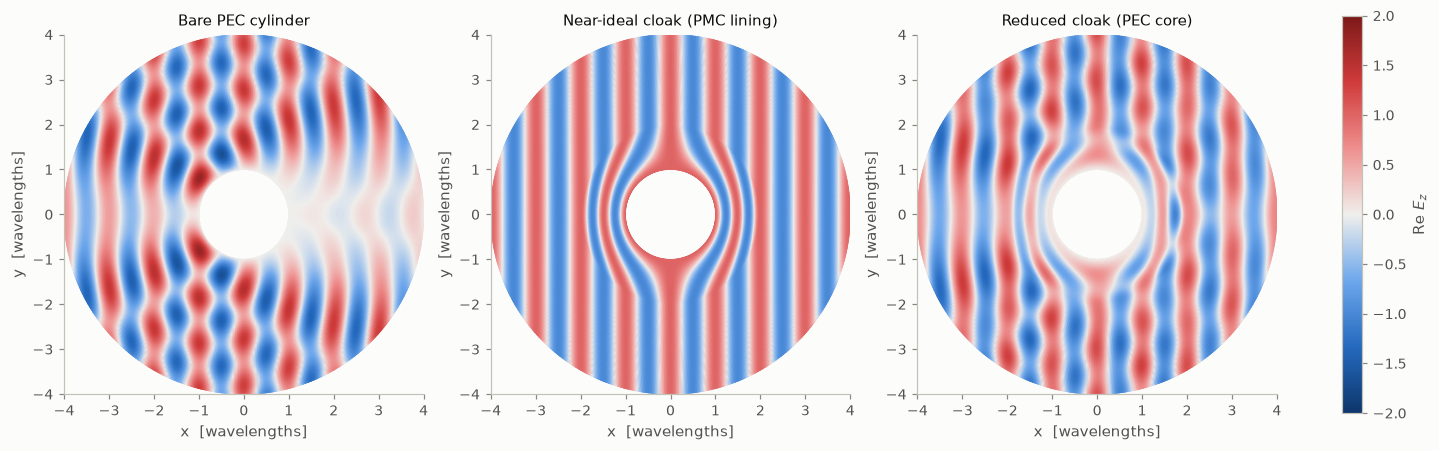

near-ideal partial-wave field vs mapped plane wave, max |dE| over r > a + 0.1: 2.73e-04
largest |s_m| of the near-ideal cloak: 1.24e-04
max |dE| minus the analytic virtual-wire field: 1.1e-14
PASS  near-ideal cloak: partial-wave field = mapped plane wave + virtual-wire field (shell): got 1.08572e-14, target 0, |diff| 1.09e-14 <= 1e-10
PASS  near-ideal cloak: deviation from the mapped plane wave is the truncated-lining field (<= 5 max|s_m|): got 0.000273201, target 0, |diff| 2.73e-04 <= 6e-04


In [14]:
def total_field(s, dense, r, th, k=K0):
    """E_z(r, theta) for a unit plane wave e^{ikx} from the partial waves; dense is None for a bare object."""
    m = np.arange(s.size); R = np.zeros((s.size, r.size), complex); out = r >= b if dense is not None else np.ones(r.size, bool)
    R[:, out] = jv(m[:, None], k * r[out]) + s[:, None] * hankel1(m[:, None], k * r[out])
    if dense is not None:
        c = jv(m, k * b) + s * hankel1(m, k * b)                # exterior amplitude at r = b
        R[:, ~out] = interior_ratio(dense, r[~out]) * c[:, None]
    coef = (1j ** m) * np.where(m == 0, 1.0, 2.0)
    return np.einsum("m,mr,mt->rt", coef, R, np.cos(m[:, None] * th[None, :]))


r_g = np.concatenate([np.linspace(a + delta, b, 160, endpoint=False), np.linspace(b, L, 120)])
th_g = np.linspace(0, 2 * np.pi, 361)
Xg, Yg = r_g[:, None] * np.cos(th_g), r_g[:, None] * np.sin(th_g)
panels = (("Bare PEC cylinder", total_field(s_bare, None, r_g, th_g)),
          ("Near-ideal cloak (PMC lining)", total_field(s_near, d_near, r_g, th_g)),
          ("Reduced cloak (PEC core)", total_field(s_red, d_red, r_g, th_g)))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, (title, E) in zip(axes, panels):
    im = ax.pcolormesh(Xg, Yg, E.real, cmap=DIV, vmin=-2, vmax=2, shading="gouraud")
    ax.set(xlabel="x  [wavelengths]", ylabel="y  [wavelengths]", title=title, aspect="equal", xlim=(-L, L), ylim=(-L, L))
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="Re $E_z$")
plt.show()

# consistency of sections 2 and 3: the near-ideal field in the shell is the mapped plane wave (exact field of section 2)
shell = (r_g[:, None] > a + 0.1) & (r_g[:, None] < b) | (r_g[:, None] >= b)
rp_g = np.where(r_g < b, b * (r_g - a) / (b - a), r_g)[:, None]
E_exact = np.exp(1j * K0 * rp_g * np.cos(th_g))
dev = np.abs(panels[1][1] - E_exact)[np.broadcast_to(shell, E_exact.shape)].max()
print(f"near-ideal partial-wave field vs mapped plane wave, max |dE| over r > a + 0.1: {dev:.2e}")
# tolerance: 5 max|s_m|; the truncated lining adds a scattered wave of order |s_m| H_m, which the exact (ideal) field does not contain
print(f"largest |s_m| of the near-ideal cloak: {np.abs(s_near).max():.2e}")
# the deviation is exactly the scattered field of the virtual wire, sum_m i^m c_m s_m H_m(k0 r'), r' the virtual radius (r' = r outside)
mm_ = np.arange(s_near.size); s_exact = ideal_coeffs(delta, "pmc", s_near.size - 1)   # analytic s_m: relative accuracy at large m, where s_m H_m is not small
cf = (1j ** mm_) * np.where(mm_ == 0, 1.0, 2.0)
scat = np.einsum("m,mr,mt->rt", cf * s_exact, hankel1(mm_[:, None], K0 * rp_g.ravel()[None, :]), np.cos(mm_[:, None] * th_g[None, :]))
in_shell = np.broadcast_to((r_g[:, None] > a + 0.1) & (r_g[:, None] < b), E_exact.shape)   # exterior excluded: there the truncated plane-wave series (m_f terms) differs from e^{ikx} at 1e-7
dev2 = np.abs(panels[1][1] - E_exact - scat)[in_shell].max()
print(f"max |dE| minus the analytic virtual-wire field: {dev2:.1e}")
# tolerance 1e-10: dense-output interpolation and ODE rounding (observed ~1e-14)
check("near-ideal cloak: partial-wave field = mapped plane wave + virtual-wire field (shell)", dev2, 1e-10)
check("near-ideal cloak: deviation from the mapped plane wave is the truncated-lining field (<= 5 max|s_m|)", dev, 5 * np.abs(s_near).max())

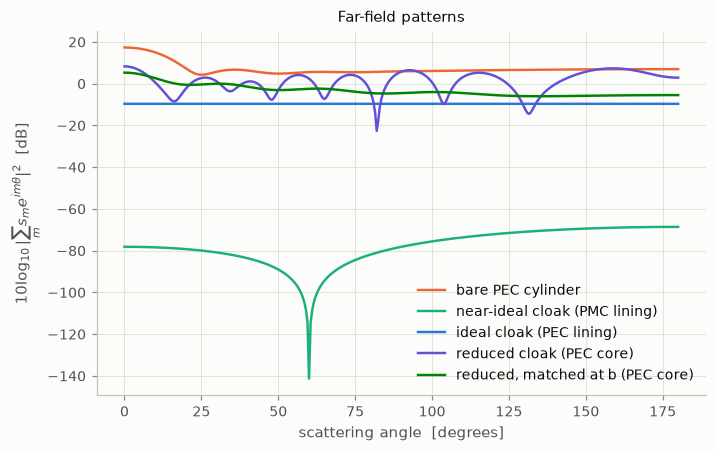

far-field pattern [dB] at selected angles:        0      30      60      90     120     150     180  deg
bare PEC                                     17.4     5.7     5.6     6.0     6.5     6.9     7.0
near-ideal                                  -78.1   -80.8  -141.3   -78.1   -72.1   -69.4   -68.6
ideal, PEC                                   -9.6    -9.6    -9.6    -9.6    -9.6    -9.6    -9.6
reduced                                       8.3     1.1     2.4     5.8     3.9     5.7     2.9
reduced, matched                                  5.3     0.0    -2.4    -4.5    -5.4    -5.8    -5.4


In [15]:
th_d = np.linspace(0, np.pi, 361)                                 # scattering angle, 0 = forward
fig, ax = plt.subplots()
for lab, s_, col in (("bare PEC cylinder", s_bare, BARE), ("near-ideal cloak (PMC lining)", s_near, PMC_C), ("ideal cloak (PEC lining)", s_ipec, PEC_C),
                     ("reduced cloak (PEC core)", s_red, REDUCED_C), ("reduced, matched at b (PEC core)", s_match, CAT[5])):
    amp = s_[0] + 2 * (s_[1:, None] * np.cos(np.arange(1, s_.size)[:, None] * th_d[None, :])).sum(0)
    ax.plot(np.degrees(th_d), 10 * np.log10(np.abs(amp) ** 2), color=col, label=lab)
ax.set(xlabel="scattering angle  [degrees]", ylabel="$10\\log_{10}|\\sum_m s_m e^{im\\theta}|^2$  [dB]", title="Far-field patterns")
ax.legend()
plt.show()
ang = np.array([0, 30, 60, 90, 120, 150, 180])
print("far-field pattern [dB] at selected angles:   " + "  ".join(f"{x:>6d}" for x in ang) + "  deg")
for lab, s_ in (("bare PEC", s_bare), ("near-ideal", s_near), ("ideal, PEC", s_ipec), ("reduced", s_red), ("reduced, matched", s_match)):
    am = s_[0] + 2 * (s_[1:, None] * np.cos(np.arange(1, s_.size)[:, None] * np.radians(ang)[None, :])).sum(0)
    print(f"{lab:<12}" + " " * 31 + "  ".join(f"{v:6.1f}" for v in 10 * np.log10(np.abs(am) ** 2)))

The reduced cloak scatters less than the bare cylinder, but with an oscillating pattern that is far from invisible. The near-ideal cloak sits far below it mostly because of its PMC lining; with the same PEC lining the ideal medium is limited by the logarithmic $m=0$ residue of section 4, and the reduced cloak is worse than that by the factor printed above. Matching the impedance removes part of the reduced width but leaves $|s_0|$ large: two causes, the outer mismatch and the uncloaked $m=0$ wave. Dependence on angle is printed under the figure.

### (b) Loss

Multiply $\mu_r,\mu_\theta,\varepsilon_z$ by $1+it$ (the impedance is untouched, the index becomes complex). To first order $s_m$ acquires an $O(t)$ part, so for small $t$ absorption should grow like $t$ and the added scattering like $t^2$; these are small-$t$ asymptotics, and the table shows both curves flattening as $t$ approaches the largest values.

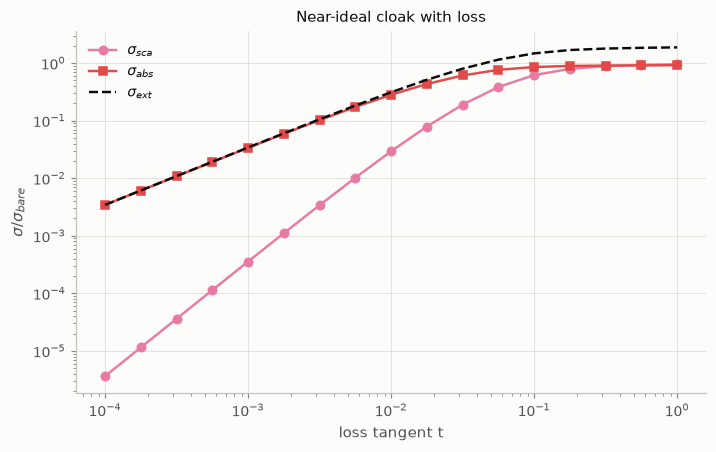

       t     sca/bare     abs/bare     ext/bare
 1.0e-04   3.6494e-06   3.4406e-03   3.4443e-03
 3.2e-04   3.6261e-05   1.0831e-02   1.0867e-02
 1.0e-03   3.5709e-04   3.3760e-02   3.4117e-02
 3.2e-03   3.4044e-03   1.0206e-01   1.0547e-01
 1.0e-02   2.9361e-02   2.8148e-01   3.1085e-01
 3.2e-02   1.8941e-01   6.0808e-01   7.9749e-01
 1.0e-01   6.1733e-01   8.5249e-01   1.4698e+00
 3.2e-01   8.8040e-01   9.0308e-01   1.7835e+00
 1.0e+00   9.5366e-01   9.1500e-01   1.8687e+00
PASS  loss: log-log slope of sigma_abs vs t (t = 1e-4..1e-3), first order: got 0.991998, target 1, |diff| 8.00e-03 <= 5e-02
PASS  loss: log-log slope of sigma_sca vs t (t = 1e-4..1e-3), second order: got 1.99087, target 2, |diff| 9.13e-03 <= 5e-02
PASS  loss: sigma_abs >= 0 for every t (min of 0 and sigma_abs): got 0, target 0, |diff| 0.00e+00 <= 1e-12


In [16]:
tan_d = np.logspace(-4, 0, 17)
loss_w = []
for t in tan_d:
    c = 1 + 1j * t
    s_ = scatter_coeffs(lambda r, p: c * ideal[0](r, p), lambda r, p: c * ideal[1](r, p), lambda r, p: c * ideal[2](r, p),
                        a + delta, b, "pmc", m_max, r0=a, rho_in=delta)
    loss_w.append(widths(s_))
loss_w = np.array(loss_w) / sig_bare
fig, ax = plt.subplots()
ax.loglog(tan_d, loss_w[:, 0], color=SCA_C, marker="o", label="$\\sigma_{sca}$")
ax.loglog(tan_d, loss_w[:, 1], color=ABS_C, marker="s", label="$\\sigma_{abs}$")
ax.loglog(tan_d, loss_w[:, 2], color=INK, ls="--", label="$\\sigma_{ext}$")
ax.set(xlabel="loss tangent t", ylabel="$\\sigma/\\sigma_{bare}$", title="Near-ideal cloak with loss")
ax.legend()
plt.show()
print(f"{'t':>8} {'sca/bare':>12} {'abs/bare':>12} {'ext/bare':>12}")
for t, w_ in zip(tan_d[::2], loss_w[::2]):
    print(f"{t:8.1e} {w_[0]:12.4e} {w_[1]:12.4e} {w_[2]:12.4e}")
sl = lambda col, i, j: np.polyfit(np.log(tan_d[i:j]), np.log(loss_w[i:j, col]), 1)[0]
# tolerance 0.05: second-order terms are O(t) <= 1e-3 relative on the fitted range t = 1e-4..1e-3
check("loss: log-log slope of sigma_abs vs t (t = 1e-4..1e-3), first order", sl(1, 0, 5), 0.05, 1.0)
check("loss: log-log slope of sigma_sca vs t (t = 1e-4..1e-3), second order", sl(0, 0, 5), 0.05, 2.0)
check("loss: sigma_abs >= 0 for every t (min of 0 and sigma_abs)", min(0.0, loss_w[:, 1].min()), 1e-12)

### (c) Layering

A realizable cloak is a stack of $N$ homogeneous anisotropic layers of equal thickness between $a+\delta$ and $b$, with the parameters sampled at the layer midpoints. The solver integrates each layer with constant $(\mu_r,\mu_\theta,\varepsilon_z)$, so the only approximation is the sampling; the PMC lining stays at $\delta=10^{-3}a$. The continuous value is the reference line. We add $N=128$ and $256$ to see the approach to the continuum; midpoint sampling is second order in the medium, so we expect $\sigma\sim N^{-4}$ (second order in amplitude) until the continuum value is reached.

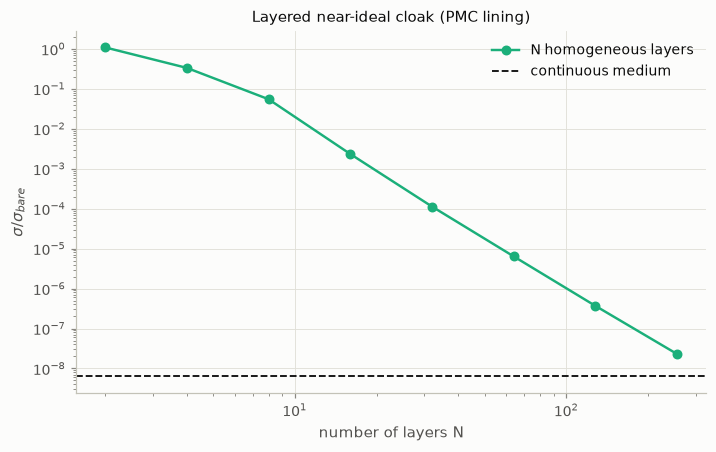

    N   sigma/sigma_bare  ratio to continuous
    2         1.0904e+00           1.6999e+08
    4         3.3427e-01           5.2109e+07
    8         5.4924e-02           8.5620e+06
   16         2.3360e-03           3.6416e+05
   32         1.1277e-04           1.7579e+04
   64         6.3773e-06           9.9415e+02
  128         3.6770e-07           5.7320e+01
  256         2.2886e-08           3.5677e+00
log-log slope of (sigma_N - sigma_continuous) vs N, N = 32..256: -4.24;  slopes of sigma_N between doublings: -1.71 -2.61 -4.56 -4.37 -4.14 -4.12 -4.01
PASS  layering: log-log slope of sigma_N vs N between N = 32 and 256 is -4: got -4.08887, target -4, |diff| 8.89e-02 <= 2e-01
PASS  layering: sigma decreases monotonically with N (1 = yes): got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  layering: N = 256 is above the continuous value (1 = yes): got 1, target 1, |diff| 0.00e+00 <= 0e+00


In [17]:
Ns = (2, 4, 8, 16, 32, 64, 128, 256)
lay_sig = []
for N in Ns:
    edges = np.linspace(a + delta, b, N + 1)[1:]; lo = np.concatenate([[a + delta], edges[:-1]]); mid = 0.5 * (lo + edges)
    lay = dict(edges=edges, mu_r=(mid - a) / mid, mu_theta=mid / (mid - a), eps_z=(b / (b - a)) ** 2 * (mid - a) / mid)
    lay_sig.append(widths(scatter_coeffs(None, None, None, a + delta, b, "pmc", m_max, r0=a, rho_in=delta, layers=lay))[0] / sig_bare)
lay_sig = np.array(lay_sig); cont_sig = widths(s_near)[0] / sig_bare
fig, ax = plt.subplots()
ax.loglog(Ns, lay_sig, color=PMC_C, marker="o", label="N homogeneous layers")
ax.axhline(cont_sig, color=INK, ls="--", lw=1.2, label="continuous medium")
ax.set(xlabel="number of layers N", ylabel="$\\sigma/\\sigma_{bare}$", title="Layered near-ideal cloak (PMC lining)")
ax.legend()
plt.show()
print(f"{'N':>5} {'sigma/sigma_bare':>18} {'ratio to continuous':>20}")
for N, v in zip(Ns, lay_sig):
    print(f"{N:5d} {v:18.4e} {v / cont_sig:20.4e}")
slope_N = np.polyfit(np.log(Ns[4:]), np.log(lay_sig[4:] - cont_sig), 1)[0]
print(f"log-log slope of (sigma_N - sigma_continuous) vs N, N = 32..256: {slope_N:.2f};  slopes of sigma_N between doublings: " + " ".join(f"{np.log2(lay_sig[i + 1] / lay_sig[i]):.2f}" for i in range(len(Ns) - 1)))
check("layering: log-log slope of sigma_N vs N between N = 32 and 256 is -4", np.log(lay_sig[-1] / lay_sig[4]) / np.log(Ns[-1] / Ns[4]), 0.2, -4.0)
check("layering: sigma decreases monotonically with N (1 = yes)", float(np.all(np.diff(lay_sig) < 0)), 0.0, 1.0)
check("layering: N = 256 is above the continuous value (1 = yes)", float(lay_sig[-1] > cont_sig), 0.0, 1.0)

### (d) Bandwidth

Every parameter value below one must come from a dispersive medium (CLAIMS.md H4). We model each such parameter with a lossless Drude form that equals the design value $p_0$ at $\omega_0$,

$$p(\omega)=1-(1-p_0)\,(\omega_0/\omega)^2,$$

keep values above one constant, and change $k_0\to k_0\,\omega/\omega_0$ in the wave equation. Here $\mu_r<1$ everywhere, $\mu_\theta>1$ everywhere, and $\varepsilon_z<1$ only in the inner part of the shell. **This dispersion model is an assumption**; the qualitative point (CLAIMS.md H1: the transformation equivalence holds frequency by frequency, so the cloak is perfect at $\omega_0$ and the question is only how the *medium* drifts) does not depend on it.

For $\omega<\omega_0$, $\mu_r(\omega)$ crosses zero at an interior radius and the radial equation has a pole for $m\ne0$. We integrate along a complex detour above the pole, which is the vanishing-loss limit for a causal medium (the zero of $\mu_r$ moves below the real axis for $\omega\to\omega+i0$), and cross-check it against explicit damping $\omega(\omega+i\gamma)$ with no contour: $\sigma_{sca}$ at $\gamma=10^{-6}$, and $\sigma_{abs}$ by extrapolating the damped values to $\gamma\to0$. This limit keeps a finite resonant absorption at the pole (the magnetic analog of resonance absorption at $\varepsilon=0$), so $\sigma_{abs}\neq0$ below $\omega_0$. At finite damping $\sigma_{abs}$ also has an ordinary bulk-loss term proportional to $\gamma$; the resonant term dominates only when $\gamma/\omega_0$ is very small, and the cell below prints the size of the bulk term.

In [18]:
CEZ = (b / (b - a)) ** 2
drude = lambda p0, w, g=0.0: 1 - (1 - p0) / (w * (w + 1j * g))


def dispersive(w, g=0.0):
    ez = lambda r, p: (lambda q: drude(q, w, g) if np.real(q) < 1 else q)(CEZ * p / r)   # only values below 1 are dispersive
    return (lambda r, p: drude(p / r, w, g)), (lambda r, p: r / p), ez


def pole_contour(w, frac=0.25):
    """Complex path r(t) detouring above the zero of mu_r(omega); real (identity) outside a window around it."""
    rs = (1 - w**2) * a / w**2                                   # rho at which mu_r(omega) = 0
    t1, t2, h = np.log(rs / 2.2), np.log(1.4 * rs), frac * rs
    assert t1 > np.log(delta)
    def contour(t):
        rho = np.exp(t)
        if t1 < t < t2:
            u = (t - t1) / (t2 - t1)
            eta, deta = h * np.sin(np.pi * u) ** 2, h * np.pi / (t2 - t1) * np.sin(2 * np.pi * u)
        else:
            eta = deta = 0.0
        return a + rho + 1j * eta, rho + 1j * eta, rho + 1j * deta
    return contour


def sigma_omega(w, g=0.0, contour=True):
    k = K0 * w; mm = int(np.ceil(k * b)) + 15
    cont = pole_contour(w) if (w < 1 - 1e-12 and contour and g == 0.0) else None
    s_ = scatter_coeffs(*dispersive(w, g), a + delta, b, "pmc", mm, r0=a, rho_in=delta, k=k, contour=cont)
    return np.array(widths(s_, k)) / widths(bare_pec(mm, k=k), k)[0]


ws = np.unique(np.round(np.concatenate([np.arange(0.90, 1.1001, 0.01), [0.995, 0.998, 1.001, 1.002, 1.005]]), 3))   # refined near 1: the notch is narrower than 0.01 (0.999 is excluded: the pole of mu_r would lie inside the truncation radius)
band = np.array([sigma_omega(w) for w in ws])
w95 = sigma_omega(0.95, g=1e-6)
g_hi, g_lo = 1e-4, 1e-5                                           # damped runs for the sigma_abs extrapolation (linear in gamma: resonant + bulk term)
a_hi, a_lo = sigma_omega(0.95, g=g_hi)[1], sigma_omega(0.95, g=g_lo)[1]
bulk = (a_hi - a_lo) / (g_hi - g_lo)                              # d sigma_abs / d gamma (units of sigma_bare)
abs_extrap = a_lo - bulk * g_lo
print(f"omega/omega0 = 0.95: sigma_abs/sigma_bare at gamma = 1e-4, 1e-5: {a_hi:.4e}, {a_lo:.4e}; extrapolated to gamma -> 0: {abs_extrap:.4e}; "
      f"complex detour: {band[list(ws).index(0.95), 1]:.4e}")
print(f"bulk-loss absorption slope d(sigma_abs/sigma_bare)/d gamma = {bulk:.1f}: at gamma = 1e-3, 1e-2 it is {bulk * 1e-3:.2e}, {bulk * 1e-2:.2e} (linear extrapolation), against the resonant term above")
check("sigma_abs at 0.95: damped runs extrapolated to gamma -> 0 vs complex detour, relative", abs_extrap / band[list(ws).index(0.95), 1] - 1, 0.05)
check("complex detour vs small damping (gamma = 1e-6) at omega/omega0 = 0.95: relative sigma_sca", band[list(ws).index(0.95), 0] / w95[0] - 1, 1e-3)   # tolerance sqrt(gamma): damping smears the pole region, which perturbs sigma at that order
check("omega = omega0 reproduces the nondispersive baseline", band[list(ws).index(1.0), 0] / cont_sig - 1, 1e-9)
check("lossless side omega >= omega0: sigma_abs", np.abs(band[ws >= 1, 1]).max(), 1e-12)

omega/omega0 = 0.95: sigma_abs/sigma_bare at gamma = 1e-4, 1e-5: 2.1600e-03, 2.6002e-04; extrapolated to gamma -> 0: 4.8920e-05; complex detour: 4.8614e-05
bulk-loss absorption slope d(sigma_abs/sigma_bare)/d gamma = 21.1: at gamma = 1e-3, 1e-2 it is 2.11e-02, 2.11e-01 (linear extrapolation), against the resonant term above
PASS  sigma_abs at 0.95: damped runs extrapolated to gamma -> 0 vs complex detour, relative: got 0.0063037, target 0, |diff| 6.30e-03 <= 5e-02
PASS  complex detour vs small damping (gamma = 1e-6) at omega/omega0 = 0.95: relative sigma_sca: got 1.56274e-05, target 0, |diff| 1.56e-05 <= 1e-03
PASS  omega = omega0 reproduces the nondispersive baseline: got -1.50104e-11, target 0, |diff| 1.50e-11 <= 1e-09
PASS  lossless side omega >= omega0: sigma_abs: got 2.73411e-15, target 0, |diff| 2.73e-15 <= 1e-12


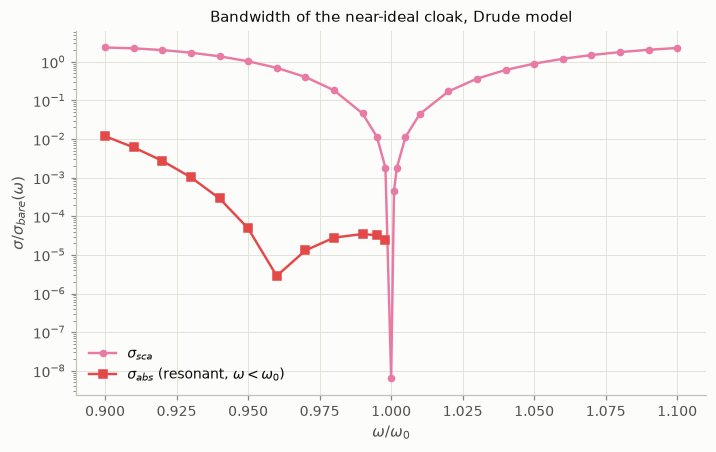

  w/w0     sca/bare     abs/bare
 0.900   2.3534e+00   1.1845e-02
 0.910   2.2338e+00   6.0976e-03
 0.920   2.0189e+00   2.7337e-03
 0.930   1.7281e+00   1.0221e-03
 0.940   1.3895e+00   2.9075e-04
 0.950   1.0352e+00   4.8614e-05
 0.960   6.9768e-01   2.8603e-06
 0.970   4.0613e-01   1.3034e-05
 0.980   1.8377e-01   2.8032e-05
 0.990   4.6064e-02   3.4845e-05
 0.995   1.1468e-02   3.2216e-05
 0.998   1.8267e-03   2.3697e-05
 1.000   6.4149e-09  -3.7892e-21
 1.001   4.5614e-04   1.2406e-17
 1.002   1.8185e-03   1.1630e-16
 1.005   1.1278e-02  -2.0916e-16
 1.010   4.4474e-02   2.7900e-16
 1.020   1.7141e-01   4.8562e-17
 1.030   3.6745e-01  -4.8601e-16
 1.040   6.1591e-01   6.8095e-16
 1.050   8.9875e-01  -7.7883e-16
 1.060   1.1983e+00   1.3640e-15
 1.070   1.4987e+00   1.7550e-15
 1.080   1.7866e+00   3.9030e-16
 1.090   2.0510e+00  -2.7341e-15
 1.100   2.2836e+00   0.0000e+00


In [19]:
fig, ax = plt.subplots()
ax.semilogy(ws, band[:, 0], color=SCA_C, marker="o", ms=4, label="$\\sigma_{sca}$")
pos = band[:, 1] > 1e-12                                          # zero absorption cannot be drawn on a log axis
ax.semilogy(ws[pos], band[pos, 1], color=ABS_C, marker="s", label="$\\sigma_{abs}$ (resonant, $\\omega<\\omega_0$)")
ax.set(xlabel="$\\omega/\\omega_0$", ylabel="$\\sigma/\\sigma_{bare}(\\omega)$", title="Bandwidth of the near-ideal cloak, Drude model")
ax.legend()
plt.show()
print(f"{'w/w0':>6} {'sca/bare':>12} {'abs/bare':>12}")
for w, v in zip(ws, band):
    print(f"{w:6.3f} {v[0]:12.4e} {v[1]:12.4e}")

## Summary

An autodiff Jacobian reproduces the book's cylindrical and spherical cloak parameters and the $-1$ of the folded map. The exact cloaked field is the pulled-back virtual field; the independent partial-wave solver reproduces it in the shell and agrees with closed forms, Mie theory and energy conservation.

The ideal cylindrical cloak is only as good as its lining. Truncated at $r=a+\delta$ it scatters like a bare wire of radius $\delta'=b\delta/(b-a)$ in virtual space. With a PEC or dielectric lining the $m=0$ term decays only like $1/\ln^2$ (see the printed factors), whereas the magnetic ("PMC") wall, the $E_z$ case of the soft-and-hard-surface lining of Greenleaf et al., decays like $\delta^4$: the quantitative face of the magnetic-surface-current requirement of CLAIMS.md H4.

The reduced parameters preserve the ray paths but leave a large residual scattering width with two causes: the impedance mismatch at $r=b$ (a matched variant removes part of it) and the $m=0$ wave, which no reduced set of this kind cloaks. Against the ideal medium with the same PEC lining the reduced cloak is worse by the printed factor; the larger gap to the PMC-lined cloak is mostly the lining. For small loss tangent absorption is linear and extra scattering quadratic; both saturate at large $t$. A layered cloak converges to the continuous one like $N^{-4}$ (printed slope). A small frequency detuning destroys the cancellation under the Drude model; below $\omega_0$ it adds resonant absorption where $\mu_r$ crosses zero, which is the vanishing-loss limit, since at realistic damping bulk loss is far larger and scattering is the main degradation.

## Caveats and open ends

- Everything is 2-D scalar TM ($E_z$). The 3-D spherical cloak is checked only at the level of principal values; its field (the book's Exercise 33.1) is not computed.
- The lining is a boundary condition (PEC, PMC or an isotropic core), not a modeled metamaterial. A PMC wall is a mathematical device satisfying $de/dr'=0$; nothing here shows that a realizable lining does this, and $\delta=10^{-12}a$ is far beyond any fabricable structure.
- The Drude model is an assumption. The complex-detour integration below $\omega_0$ gives the vanishing-loss limit, whose resonant absorption depends on the slope of $\mu_r(\omega)$ at its zero; it was cross-checked against explicit damping at one frequency only ($\sigma_{sca}$ directly, $\sigma_{abs}$ by extrapolation in $\gamma$).
- Loss, layering and bandwidth are computed for one baseline ($\delta=10^{-3}a$, PMC lining). Other linings or $\delta$ were not tested.

## References

- A. Greenleaf, Y. Kurylev, M. Lassas and G. Uhlmann, Full-wave invisibility of active devices at all frequencies, *Commun. Math. Phys.* 275, 749 (2007); and Improvement of cylindrical cloaking with the SHS lining, *Opt. Express* 15, 12717 (2007).
- M. Yan, Z. Ruan and M. Qiu, Cylindrical invisibility cloak with simplified material parameters is inherently visible, *Phys. Rev. Lett.* 99, 233901 (2007).
- U. Leonhardt and T. Philbin, *Geometry and Light* (Dover, 2010): sections 26-28 (the recipe, (26.7), (28.3), (28.4)), 32 (cylindrical transformation media, (32.5), (32.11), (32.16)-(32.19)), 33 (spherical cloak, (33.3)-(33.5)), 34 (folded space, (34.1)-(34.2)).
- J. B. Pendry, D. Schurig and D. R. Smith, Controlling electromagnetic fields, *Science* 312, 1780 (2006).
- U. Leonhardt, Optical conformal mapping, *Science* 312, 1777 (2006).
- D. Schurig et al., Metamaterial electromagnetic cloak at microwave frequencies, *Science* 314, 977 (2006): the reduced parameter set.
- Z. Ruan, M. Yan, C. W. Neff and M. Qiu, Ideal cylindrical cloak: perfect but sensitive to tiny perturbations, *Phys. Rev. Lett.* 99, 113903 (2007).
- Reading notes on the book, CLAIMS.md (H1, H3, H4, H5) and ERRATA.md (E5.1), in `references/geometry-and-light-notes/`.